In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
import sys, os

sys.path.insert(0, os.path.join(os.getcwd(), "..", "scripts"))
from utility_functions import read_fasta, read_parrot_preds

# Synthetic sequences

In [2]:
# read in preds and convert to single value
synthetics_no_tada = read_parrot_preds('synthetics_preds_no_tada_model.csv')
synthetics_no_tada = synthetics_no_tada.rename(columns={'preds' : 'no_tada_preds'})
synthetics_no_tada['no_tada_max_value'] = [max([float(a) for a in ls]) for ls in (synthetics_no_tada['no_tada_preds'])]
synthetics_no_tada['no_tada_mean_value'] = [np.mean([float(a) for a in ls]) for ls in (synthetics_no_tada['no_tada_preds'])]

synthetics_no_adpred = read_parrot_preds('synthetics_preds_no_adpred_model.csv')
synthetics_no_adpred = synthetics_no_adpred.rename(columns={'preds' : 'no_adpred_preds'})
synthetics_no_adpred['no_adpred_max_value'] = [max([float(a) for a in ls]) for ls in (synthetics_no_adpred['no_adpred_preds'])]
synthetics_no_adpred['no_adpred_mean_value'] = [np.mean([float(a) for a in ls]) for ls in (synthetics_no_adpred['no_adpred_preds'])]

synthetics_no_adhunterlite = read_parrot_preds('synthetics_preds_no_adhunterlite_model.csv')
synthetics_no_adhunterlite = synthetics_no_adhunterlite.rename(columns={'preds' : 'no_adhunter_l_preds'})
synthetics_no_adhunterlite['no_adhunter_l_max_value'] = [max([float(a) for a in ls]) for ls in (synthetics_no_adhunterlite['no_adhunter_l_preds'])]
synthetics_no_adhunterlite['no_adhunter_l_mean_value'] = [np.mean([float(a) for a in ls]) for ls in (synthetics_no_adhunterlite['no_adhunter_l_preds'])]

synthetics_no_adhunterensemble = read_parrot_preds('synthetics_preds_no_adhunterensemble_model.csv')
synthetics_no_adhunterensemble = synthetics_no_adhunterensemble.rename(columns={'preds' : 'no_adhunter_e_preds'})
synthetics_no_adhunterensemble['no_adhunter_e_max_value'] = [max([float(a) for a in ls]) for ls in (synthetics_no_adhunterensemble['no_adhunter_e_preds'])]
synthetics_no_adhunterensemble['no_adhunter_e_mean_value'] = [np.mean([float(a) for a in ls]) for ls in (synthetics_no_adhunterensemble['no_adhunter_e_preds'])]

synthetics_no_paddle = read_parrot_preds('synthetics_preds_no_paddle_model.csv')
synthetics_no_paddle = synthetics_no_paddle.rename(columns={'preds' : 'no_paddle_preds'})
synthetics_no_paddle['no_paddle_max_value'] = [max([float(a) for a in ls]) for ls in (synthetics_no_paddle['no_paddle_preds'])]
synthetics_no_paddle['no_paddle_mean_value'] = [np.mean([float(a) for a in ls]) for ls in (synthetics_no_paddle['no_paddle_preds'])]

synthetics_no_sanjana = read_parrot_preds('synthetics_preds_no_sanjana_model.csv')
synthetics_no_sanjana = synthetics_no_sanjana.rename(columns={'preds' : 'no_sanjana_preds'})
synthetics_no_sanjana['no_sanjana_max_value'] = [max([float(a) for a in ls]) for ls in (synthetics_no_sanjana['no_sanjana_preds'])]
synthetics_no_sanjana['no_sanjana_mean_value'] = [np.mean([float(a) for a in ls]) for ls in (synthetics_no_sanjana['no_sanjana_preds'])]

synthetics_all_six = read_parrot_preds('../regression/synthetics/synthetics_preds_parrot_all_six_model.csv')
synthetics_all_six = synthetics_all_six.rename(columns={'preds' : 'all_six_preds'})
synthetics_all_six['all_six_max_value'] = [max([float(a) for a in ls]) for ls in (synthetics_all_six['all_six_preds'])]
synthetics_all_six['all_six_mean_value'] = [np.mean([float(a) for a in ls]) for ls in (synthetics_all_six['all_six_preds'])]

In [3]:
experimental = pd.read_csv('../regression/synthetics/Synthetics_Activities.csv')
experimental = experimental.rename(columns = {'AAseq' : 'sequence'})

In [4]:
all_merged = synthetics_no_tada.merge(
                experimental, on='sequence').merge(
                    synthetics_no_adpred, on=['sequence', 'name']).merge(
                        synthetics_no_adhunterensemble, on=['sequence', 'name']).merge(
                            synthetics_no_adhunterlite, on=['sequence', 'name']).merge(
                                synthetics_no_sanjana, on=['sequence', 'name']).merge(
                                    synthetics_no_paddle, on=['sequence', 'name']).merge(
                                        synthetics_all_six, on=['sequence', 'name'])

In [5]:
all_merged.to_csv('synthetic_leave_one_out_results_merged.csv')

In [6]:
# Merge with experimental 
synthetics_no_paddle_merged = synthetics_no_paddle.merge(experimental, left_on='sequence', right_on='sequence')
synthetics_no_adpred_merged = synthetics_no_adpred.merge(experimental, left_on='sequence', right_on='sequence')
synthetics_no_adhunterensemble_merged = synthetics_no_adhunterensemble.merge(experimental, left_on='sequence', right_on='sequence')
synthetics_no_adhunterlite_merged = synthetics_no_adhunterlite.merge(experimental, left_on='sequence', right_on='sequence')
synthetics_no_tada_merged = synthetics_no_tada.merge(experimental, left_on='sequence', right_on='sequence')
synthetics_no_sanjana_merged = synthetics_no_sanjana.merge(experimental, left_on='sequence', right_on='sequence')
synthetics_all_six_merged = synthetics_all_six.merge(experimental, left_on='sequence', right_on='sequence')



In [8]:
def make_leave_one_out_scatter(df, col, axs, i): 
    # Paddle
    
    axs[0, i].scatter(df[f'no_{col}_max_value'], 
                    df['Activity'], 
                    alpha=0.2, 
                    s=5,
                    edgecolor=color_dict[col],
                    linewidths=0.2, 
                    color='grey')

    pearson_corr, pearson_p = pearsonr(df[f'no_{col}_max_value'], 
                                    df['Activity'])
    spearman_corr, spearman_p = spearmanr(df[f'no_{col}_max_value'], 
                                        df['Activity'])
    axs[0, i].set_xlabel(f'no_{col}_max_value')
    axs[0, i].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")

    axs[1, i].scatter(df[f'no_{col}_mean_value'], 
                    df['Activity'],
                    alpha=0.2,
                    s=5,
                    edgecolor=color_dict[col],
                    linewidths=0.2, 
                    color='grey')
    pearson_corr, pearson_p = pearsonr(df[f'no_{col}_mean_value'], 
                                    df['Activity'])
    spearman_corr, spearman_p = spearmanr(df[f'no_{col}_mean_value'], 
                                        df['Activity'])
    axs[1, i].set_xlabel(f'no_{col}_mean_value')
    axs[1, i].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")

In [9]:
def make_all_six_scatter(df, col, axs, i): 
    # Paddle
    
    axs[0, i].scatter(df[f'{col}_max_value'], 
                    df['Activity'], 
                    alpha=0.2, 
                    s=5,
                    edgecolor=color_dict[col],
                    linewidths=0.2, 
                    color='grey')

    pearson_corr, pearson_p = pearsonr(df[f'{col}_max_value'], 
                                    df['Activity'])
    spearman_corr, spearman_p = spearmanr(df[f'{col}_max_value'], 
                                        df['Activity'])
    axs[0, i].set_xlabel(f'{col}_max_value')
    axs[0, i].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")

    axs[1, i].scatter(df[f'{col}_mean_value'], 
                    df['Activity'],
                    alpha=0.2,
                    s=5,
                    edgecolor=color_dict[col],
                    linewidths=0.2, 
                    color='grey')
    pearson_corr, pearson_p = pearsonr(df[f'{col}_mean_value'], 
                                    df['Activity'])
    spearman_corr, spearman_p = spearmanr(df[f'{col}_mean_value'], 
                                        df['Activity'])
    axs[1, i].set_xlabel(f'{col}_mean_value')
    axs[1, i].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")

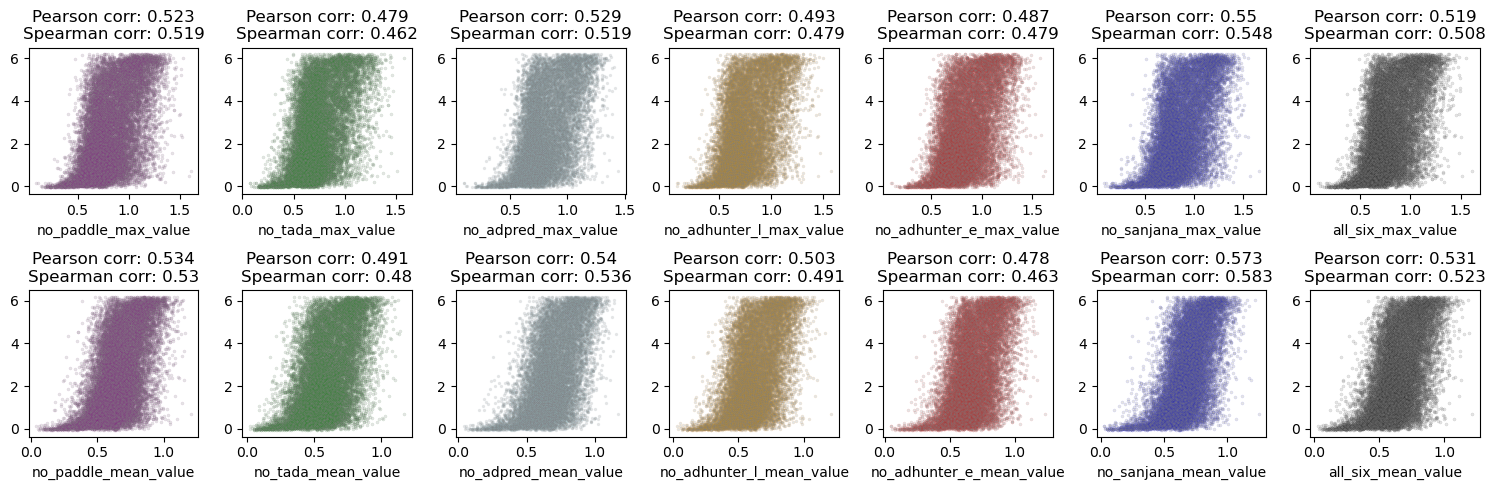

In [10]:
color_dict = {
    'tada' : 'green', 
    'adpred' : 'lightblue',
    'adhunter_e' : 'red',
    'adhunter_l' : 'orange', 
    'paddle' : 'purple', 
    'sanjana' : 'blue',
    'all_six' : 'black'
}

# def make_scatterplot(screen):
fig, axs = plt.subplots(2, 7, figsize=(15, 5))

make_leave_one_out_scatter(synthetics_no_paddle_merged, 'paddle', axs, 0)
make_leave_one_out_scatter(synthetics_no_tada_merged, 'tada', axs, 1)
make_leave_one_out_scatter(synthetics_no_adpred_merged, 'adpred', axs, 2)
make_leave_one_out_scatter(synthetics_no_adhunterlite_merged, 'adhunter_l', axs, 3)
make_leave_one_out_scatter(synthetics_no_adhunterensemble_merged, 'adhunter_e', axs, 4)
make_leave_one_out_scatter(synthetics_no_sanjana_merged, 'sanjana', axs, 5)
make_all_six_scatter(synthetics_all_six_merged, 'all_six', axs, 6)

fig.tight_layout()
plt.savefig(f"../figures/leave_one_out_synthetics_scatter_plots.pdf", format='pdf', bbox_inches='tight')
plt.savefig(f"../figures/leave_one_out_synthetics_scatter_plots.png", format='png', bbox_inches='tight')

# Other test sequences

In [18]:
# read in preds and convert to single value
test_no_tada = read_parrot_preds('all_test_preds_no_tada_model.csv')
test_no_tada = test_no_tada.rename(columns={'preds' : 'no_tada_preds'}).drop(columns=['name'])
test_no_tada['no_tada_max_value'] = [max([float(a) for a in ls]) for ls in (test_no_tada['no_tada_preds'])]
test_no_tada['no_tada_mean_value'] = [np.mean([float(a) for a in ls]) for ls in (test_no_tada['no_tada_preds'])]

test_no_adpred = read_parrot_preds('all_test_preds_no_adpred_model.csv')
test_no_adpred = test_no_adpred.rename(columns={'preds' : 'no_adpred_preds'}).drop(columns=['name'])
test_no_adpred['no_adpred_max_value'] = [max([float(a) for a in ls]) for ls in (test_no_adpred['no_adpred_preds'])]
test_no_adpred['no_adpred_mean_value'] = [np.mean([float(a) for a in ls]) for ls in (test_no_adpred['no_adpred_preds'])]

test_no_adhunterlite = read_parrot_preds('all_test_preds_no_adhunterlite_model.csv')
test_no_adhunterlite = test_no_adhunterlite.rename(columns={'preds' : 'no_adhunter_l_preds'}).drop(columns=['name'])
test_no_adhunterlite['no_adhunter_l_max_value'] = [max([float(a) for a in ls]) for ls in (test_no_adhunterlite['no_adhunter_l_preds'])]
test_no_adhunterlite['no_adhunter_l_mean_value'] = [np.mean([float(a) for a in ls]) for ls in (test_no_adhunterlite['no_adhunter_l_preds'])]

test_no_adhunterensemble = read_parrot_preds('all_test_preds_no_adhunterensemble_model.csv')
test_no_adhunterensemble = test_no_adhunterensemble.rename(columns={'preds' : 'no_adhunter_e_preds'}).drop(columns=['name'])
test_no_adhunterensemble['no_adhunter_e_max_value'] = [max([float(a) for a in ls]) for ls in (test_no_adhunterensemble['no_adhunter_e_preds'])]
test_no_adhunterensemble['no_adhunter_e_mean_value'] = [np.mean([float(a) for a in ls]) for ls in (test_no_adhunterensemble['no_adhunter_e_preds'])]

test_no_paddle = read_parrot_preds('all_test_preds_no_paddle_model.csv')
test_no_paddle = test_no_paddle.rename(columns={'preds' : 'no_paddle_preds'}).drop(columns=['name'])
test_no_paddle['no_paddle_max_value'] = [max([float(a) for a in ls]) for ls in (test_no_paddle['no_paddle_preds'])]
test_no_paddle['no_paddle_mean_value'] = [np.mean([float(a) for a in ls]) for ls in (test_no_paddle['no_paddle_preds'])]

test_no_sanjana = read_parrot_preds('all_test_preds_no_sanjana_model.csv')
test_no_sanjana = test_no_sanjana.rename(columns={'preds' : 'no_sanjana_preds'}).drop(columns=['name'])
test_no_sanjana['no_sanjana_max_value'] = [max([float(a) for a in ls]) for ls in (test_no_sanjana['no_sanjana_preds'])]
test_no_sanjana['no_sanjana_mean_value'] = [np.mean([float(a) for a in ls]) for ls in (test_no_sanjana['no_sanjana_preds'])]

test_all_six = read_parrot_preds('../regression/test_seqs/test_preds_parrot_all_six_model.csv')
test_all_six = test_all_six.rename(columns={'preds' : 'all_six_preds'}).drop(columns=['name'])
test_all_six['all_six_max_value'] = [max([float(a) for a in ls]) for ls in (test_all_six['all_six_preds'])]
test_all_six['all_six_mean_value'] = [np.mean([float(a) for a in ls]) for ls in (test_all_six['all_six_preds'])]

In [31]:
experimental = pd.read_csv('../regression/screen_test_seqs_with_activities.csv', index_col=0)
experimental = experimental.rename(columns={'protein sequence' : "sequence", 'activity' : 'Activity'})
# Don't use hummel or arnold for regression tests so drop them
experimental = experimental[~experimental['screen'].isin(['hummel', 'arnold'])].reset_index(drop=True)


In [33]:
# Merge with experimental 
test_no_paddle_merged = test_no_paddle.merge(experimental, left_on='sequence', right_on='sequence')
test_no_adpred_merged = test_no_adpred.merge(experimental, left_on='sequence', right_on='sequence')
test_no_adhunterensemble_merged = test_no_adhunterensemble.merge(experimental, left_on='sequence', right_on='sequence')
test_no_adhunterlite_merged = test_no_adhunterlite.merge(experimental, left_on='sequence', right_on='sequence')
test_no_tada_merged = test_no_tada.merge(experimental, left_on='sequence', right_on='sequence')
test_no_sanjana_merged = test_no_sanjana.merge(experimental, left_on='sequence', right_on='sequence')
test_all_six_merged = test_all_six.merge(experimental, left_on='sequence', right_on='sequence')

In [34]:
test_seqs_all_merged = test_no_tada.merge(
                            experimental, on='sequence').merge(
                                test_no_adpred, on='sequence').merge(
                                    test_no_adhunterensemble, on='sequence').merge(
                                        test_no_adhunterlite, on='sequence').merge(
                                            test_no_sanjana, on='sequence').merge(
                                                test_no_paddle, on='sequence').merge(
                                                    test_all_six, on='sequence')

In [24]:
test_seqs_all_merged.to_csv('test_seqs_leave_one_out_results_merged.csv')

In [69]:
def make_individual_scatter_screen(df, col, axs, i, screen): 
    # Paddle
    
    axs[0, i].scatter(df[df['screen'] == screen][f'max_value'], 
                    df[df['screen'] == screen]['activity'], 
                    alpha=0.2, 
                    s=5,
                    edgecolor=color_dict[col],
                    linewidths=0.2, 
                    color='grey')

    pearson_corr, pearson_p = pearsonr(df[df['screen'] == screen][f'max_value'], 
                                    df[df['screen'] == screen]['activity'])
    spearman_corr, spearman_p = spearmanr(df[df['screen'] == screen][f'max_value'], 
                                        df[df['screen'] == screen]['activity'])
    axs[0, i].set_xlabel(f'max_value')
    axs[0, i].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")

    axs[1, i].scatter(df[df['screen'] == screen][f'mean_value'], 
                    df[df['screen'] == screen]['activity'],
                    alpha=0.2,
                    s=5,
                    edgecolor=color_dict[col],
                    linewidths=0.2, 
                    color='grey')
    pearson_corr, pearson_p = pearsonr(df[df['screen'] == screen][f'mean_value'], 
                                    df[df['screen'] == screen]['activity'])
    spearman_corr, spearman_p = spearmanr(df[df['screen'] == screen][f'mean_value'], 
                                        df[df['screen'] == screen]['activity'])
    axs[1, i].set_xlabel(f'mean_value')
    axs[1, i].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")

In [26]:
help(make_leave_one_out_scatter)

Help on function make_leave_one_out_scatter in module __main__:

make_leave_one_out_scatter(df, col, axs, i)



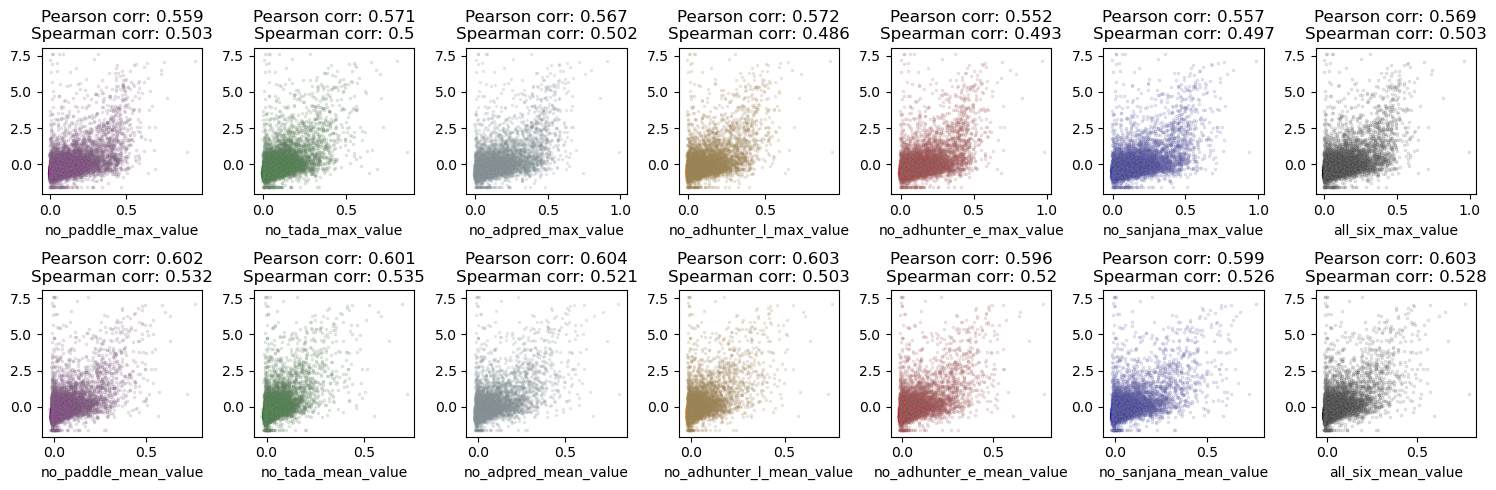

In [38]:
color_dict = {
    'tada' : 'green', 
    'adpred' : 'lightblue',
    'adhunter_e' : 'red',
    'adhunter_l' : 'orange', 
    'paddle' : 'purple', 
    'sanjana' : 'blue',
    'all_six' : 'black'
}

# def make_scatterplot(screen):
fig, axs = plt.subplots(2, 7, figsize=(15, 5))
screen = 'arf'
df = test_seqs_all_merged[test_seqs_all_merged['screen'] == screen]
make_leave_one_out_scatter(df, 'paddle', axs, 0)
make_leave_one_out_scatter(df, 'tada', axs, 1)
make_leave_one_out_scatter(df, 'adpred', axs, 2)
make_leave_one_out_scatter(df, 'adhunter_l', axs, 3)
make_leave_one_out_scatter(df, 'adhunter_e', axs, 4)
make_leave_one_out_scatter(df, 'sanjana', axs, 5)
make_all_six_scatter(df, 'all_six', axs, 6)

fig.tight_layout()
plt.savefig(f"../figures/leave_one_out_{screen}_scatter_plots.pdf", format='pdf', bbox_inches='tight')
plt.savefig(f"../figures/leave_one_out_{screen}_scatter_plots.png", format='png', bbox_inches='tight')

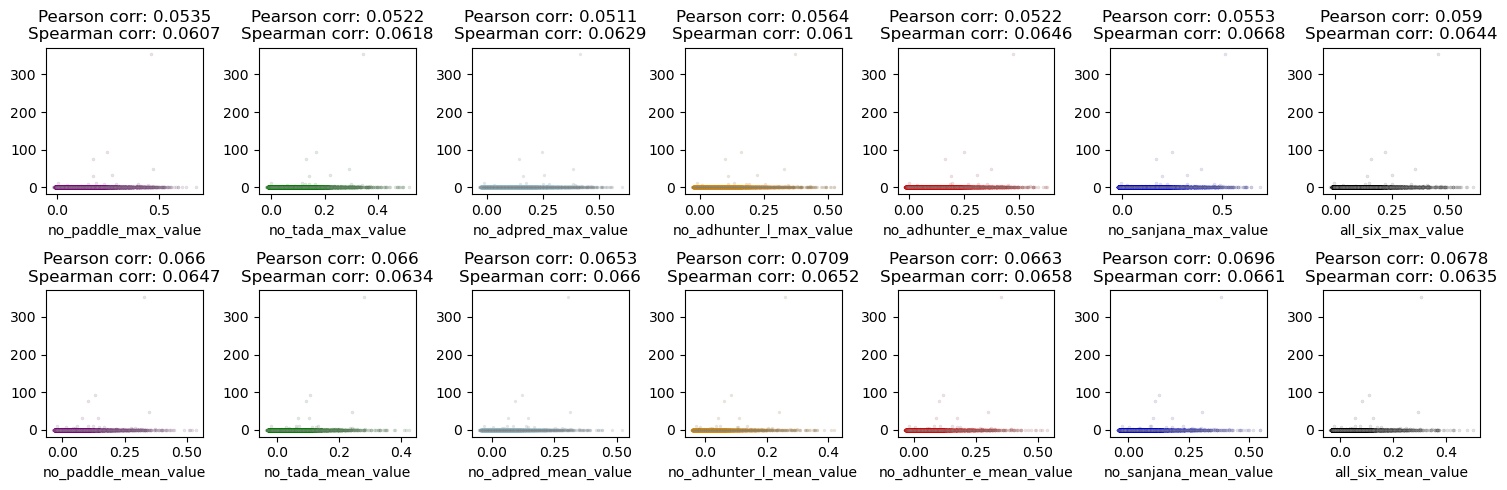

In [40]:
# def make_scatterplot(screen):
fig, axs = plt.subplots(2, 7, figsize=(15, 5))
screen = 'ravarani'
df = test_seqs_all_merged[test_seqs_all_merged['screen'] == screen]
make_leave_one_out_scatter(df, 'paddle', axs, 0)
make_leave_one_out_scatter(df, 'tada', axs, 1)
make_leave_one_out_scatter(df, 'adpred', axs, 2)
make_leave_one_out_scatter(df, 'adhunter_l', axs, 3)
make_leave_one_out_scatter(df, 'adhunter_e', axs, 4)
make_leave_one_out_scatter(df, 'sanjana', axs, 5)
make_all_six_scatter(df, 'all_six', axs, 6)

fig.tight_layout()
plt.savefig(f"../figures/leave_one_out_{screen}_scatter_plots.pdf", format='pdf', bbox_inches='tight')
plt.savefig(f"../figures/leave_one_out_{screen}_scatter_plots.png", format='png', bbox_inches='tight')

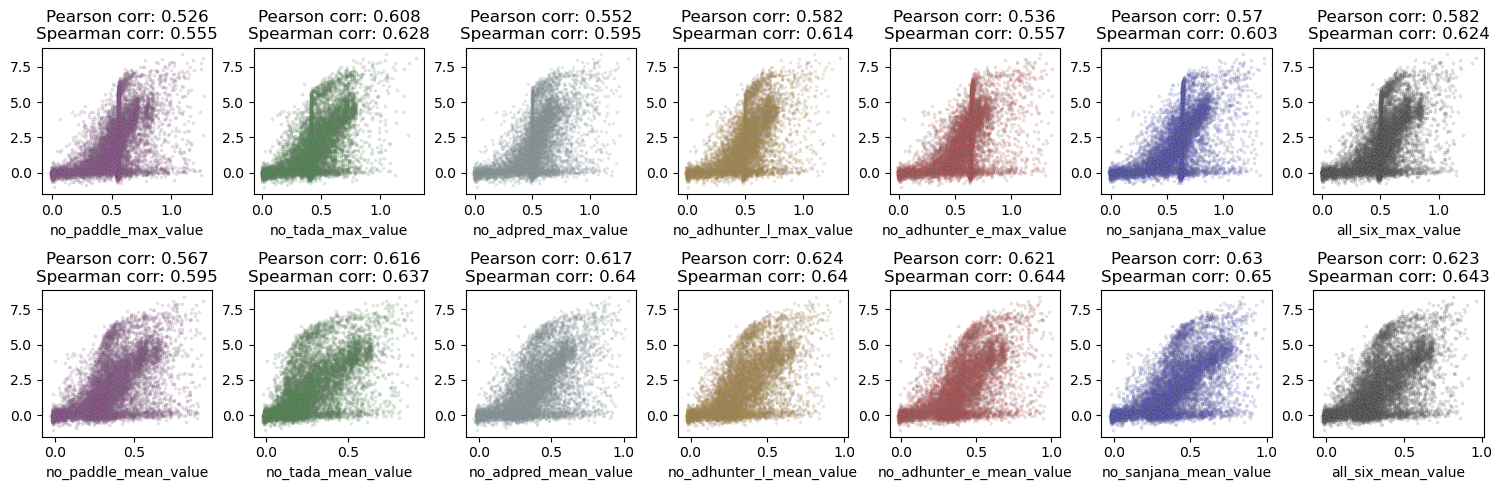

In [41]:
# def make_scatterplot(screen):
fig, axs = plt.subplots(2, 7, figsize=(15, 5))
screen = 'sanborn'

df = test_seqs_all_merged[test_seqs_all_merged['screen'] == screen]
make_leave_one_out_scatter(df, 'paddle', axs, 0)
make_leave_one_out_scatter(df, 'tada', axs, 1)
make_leave_one_out_scatter(df, 'adpred', axs, 2)
make_leave_one_out_scatter(df, 'adhunter_l', axs, 3)
make_leave_one_out_scatter(df, 'adhunter_e', axs, 4)
make_leave_one_out_scatter(df, 'sanjana', axs, 5)
make_all_six_scatter(df, 'all_six', axs, 6)

fig.tight_layout()
plt.savefig(f"../figures/leave_one_out_{screen}_scatter_plots.pdf", format='pdf', bbox_inches='tight')
plt.savefig(f"../figures/leave_one_out_{screen}_scatter_plots.png", format='png', bbox_inches='tight')

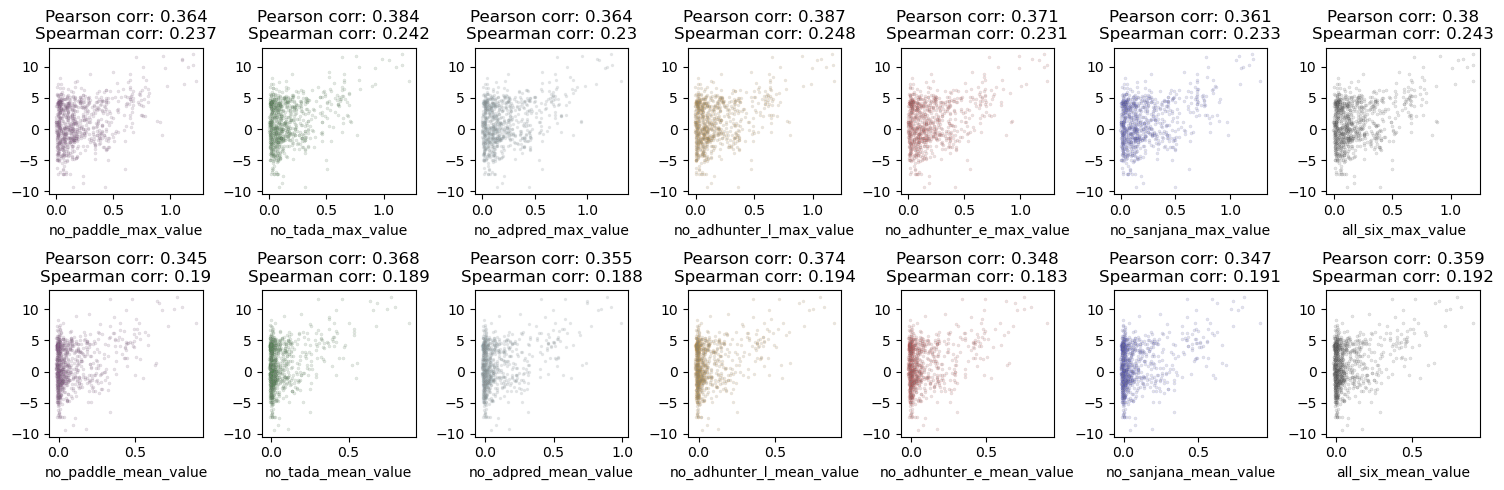

In [42]:
# def make_scatterplot(screen):
fig, axs = plt.subplots(2, 7, figsize=(15, 5))
screen = 'delrosso'

df = test_seqs_all_merged[test_seqs_all_merged['screen'] == screen]
make_leave_one_out_scatter(df, 'paddle', axs, 0)
make_leave_one_out_scatter(df, 'tada', axs, 1)
make_leave_one_out_scatter(df, 'adpred', axs, 2)
make_leave_one_out_scatter(df, 'adhunter_l', axs, 3)
make_leave_one_out_scatter(df, 'adhunter_e', axs, 4)
make_leave_one_out_scatter(df, 'sanjana', axs, 5)
make_all_six_scatter(df, 'all_six', axs, 6)

fig.tight_layout()
plt.savefig(f"../figures/leave_one_out_{screen}_scatter_plots.pdf", format='pdf', bbox_inches='tight')
plt.savefig(f"../figures/leave_one_out_{screen}_scatter_plots.png", format='png', bbox_inches='tight')